# Model 2 — Dynamic Harmonic Regression (ARIMA + Fourier Terms)

Uses `timeSeries/dataset/train.csv`, `val.csv`, and `test.csv`; target is `trip_count`, modeled separately for each `PULocationID`.

Workflow: daily (24-hour) and weekly (168-hour) Fourier regressors + ARIMA errors; select a small configuration grid by validation MAE; compare with a 168-hour seasonal-naive baseline; refit on train + validation; evaluate the untouched test set.

Forecasts are fixed-origin multi-step forecasts. Actual future target values are never fed into predictions. MAPE excludes rows with zero actual demand and reports the excluded count/percentage.

**Note:** Running per-zone SARIMAX can take time. Missing zone-hours are filled with zero; verify this is appropriate for your dataset's meaning of missing rows.

In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

cwd = Path.cwd()
if (cwd / "timeSeries" / "dataset").exists():
    ROOT = cwd
elif cwd.name == "timeSeries" and (cwd / "dataset").exists():
    ROOT = cwd.parent
else:
    ROOT = cwd
DATA = ROOT / "timeSeries" / "dataset"
OUT = ROOT / "timeSeries" / "results" / "model_2" / "Split751515"
OUT.mkdir(parents=True, exist_ok=True)

paths = {name: DATA / f"{name}.csv" for name in ("train", "val", "test")}
for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run this notebook from the repository root or update DATA.")

frames = {name: pd.read_csv(path, parse_dates=["pickup_hour"]) for name, path in paths.items()}
required = {"PULocationID", "pickup_hour", "trip_count"}
for name, df in frames.items():
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name}.csv missing columns: {sorted(missing)}")
    df["trip_count"] = pd.to_numeric(df["trip_count"], errors="coerce")
    df.dropna(subset=["PULocationID", "pickup_hour", "trip_count"], inplace=True)
    df.sort_values(["PULocationID", "pickup_hour"], inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"{name}: rows={len(df):,}, zones={df.PULocationID.nunique()}, "
          f"timestamps={df.pickup_hour.nunique()}, range={df.pickup_hour.min()} -> {df.pickup_hour.max()}")

train, val, test = frames["train"], frames["val"], frames["test"]
assert train.pickup_hour.max() < val.pickup_hour.min()
assert val.pickup_hour.max() < test.pickup_hour.min()
print("Chronological split checks passed.")

train: rows=403,374, zones=138, timestamps=2923, range=2025-09-08 00:00:00 -> 2026-01-07 18:00:00
val: rows=86,388, zones=138, timestamps=626, range=2026-01-07 19:00:00 -> 2026-02-02 20:00:00
test: rows=86,526, zones=138, timestamps=627, range=2026-02-02 21:00:00 -> 2026-02-28 23:00:00
Chronological split checks passed.


## Configuration and helper functions

The small grid is designed to keep runtime reasonable. If your environment struggles, reduce `FOURIER_GRID` or `ARIMA_GRID`.

In [3]:
FOURIER_GRID = [(2, 2), (3, 3)]  # (daily harmonics, weekly harmonics)
ARIMA_GRID = [(1, 0, 1), (2, 0, 1)]
MIN_TRAIN_POINTS = 24 * 14
PERIOD = 168

def fourier(index, daily_k, weekly_k):
    idx = pd.DatetimeIndex(index)
    t = ((idx - pd.Timestamp("1970-01-01")) / pd.Timedelta(hours=1)).to_numpy(dtype=float)
    cols = {}
    for period, kmax, label in [(24.0, daily_k, "daily"), (168.0, weekly_k, "weekly")]:
        for k in range(1, kmax + 1):
            cols[f"{label}_sin_{k}"] = np.sin(2 * np.pi * k * t / period)
            cols[f"{label}_cos_{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=idx)

def zone_series(frame, zone):
    s = (frame.loc[frame.PULocationID == zone, ["pickup_hour", "trip_count"]]
         .groupby("pickup_hour")["trip_count"].sum().sort_index())
    if s.empty:
        return pd.Series(dtype=float)
    full = pd.date_range(s.index.min(), s.index.max(), freq="h")
    s = s.reindex(full).fillna(0.0).astype(float)
    s.index.name = "pickup_hour"
    return s

def seasonal_naive(history, forecast_index, period=PERIOD):
    hist = list(np.asarray(history, dtype=float))
    preds = []
    for _ in forecast_index:
        p = hist[-period] if len(hist) >= period else (hist[-1] if hist else 0.0)
        p = max(0.0, float(p))
        preds.append(p)
        hist.append(p)
    return np.asarray(preds)

def metrics(actual, predicted):
    a, p = np.asarray(actual, float), np.asarray(predicted, float)
    ok = np.isfinite(a) & np.isfinite(p)
    a, p = a[ok], p[ok]
    if not len(a):
        return {"n_rows": 0, "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                "MAPE_pct": np.nan, "mape_excluded_zero_count": 0, "mape_excluded_zero_pct": np.nan}
    nz = a != 0
    return {
        "n_rows": len(a),
        "MAE": mean_absolute_error(a, p),
        "RMSE": float(np.sqrt(mean_squared_error(a, p))),
        "R2": r2_score(a, p) if len(a) >= 2 else np.nan,
        "MAPE_pct": float(np.mean(np.abs((a[nz] - p[nz]) / a[nz])) * 100) if nz.any() else np.nan,
        "mape_excluded_zero_count": int((~nz).sum()),
        "mape_excluded_zero_pct": float((~nz).mean() * 100),
    }

def fit_dhr(history, forecast_index, daily_k, weekly_k, order):
    if len(history) < MIN_TRAIN_POINTS:
        raise ValueError(f"insufficient history: {len(history)} hourly points")
    x_train = fourier(history.index, daily_k, weekly_k)
    x_future = fourier(forecast_index, daily_k, weekly_k)
    model = SARIMAX(np.asarray(history, float), exog=x_train.to_numpy(), order=order,
                    trend="c", enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    pred = fitted.get_forecast(steps=len(forecast_index), exog=x_future.to_numpy()).predicted_mean
    converged = bool(getattr(fitted, "mle_retvals", {}).get("converged", True))
    return np.maximum(np.asarray(pred, float), 0.0), converged

zones = sorted(set(train.PULocationID) | set(val.PULocationID) | set(test.PULocationID))
print(f"Zones: {len(zones)}")

Zones: 138


## Validation tuning

Each zone is fitted independently. The validation horizon is forecast from the end of training, without updating with actual validation demand. Candidate selection uses pooled validation MAE across all available zone-hour predictions.

In [4]:
tune_rows, val_candidate_predictions, failures = [], [], []
val_index = pd.date_range(val.pickup_hour.min(), val.pickup_hour.max(), freq="h")

for zi, zone in enumerate(zones, start=1):
    hist = zone_series(train, zone)
    actual_zone = val.loc[val.PULocationID == zone, ["PULocationID", "pickup_hour", "trip_count"]]
    if hist.empty or actual_zone.empty:
        continue
    if len(hist) < MIN_TRAIN_POINTS:
        failures.append({"split": "validation", "PULocationID": zone, "model": "DHR", "status": "insufficient_history"})
        continue

    # Baseline validation predictions
    base = pd.Series(seasonal_naive(hist.values, val_index), index=val_index)
    for row in actual_zone.itertuples(index=False):
        val_candidate_predictions.append({"PULocationID": zone, "pickup_hour": row.pickup_hour,
            "actual": row.trip_count, "predicted": float(base.loc[row.pickup_hour]), "model": "SeasonalNaive168"})

    for dk, wk in FOURIER_GRID:
        for order in ARIMA_GRID:
            label = f"DHR_D{dk}_W{wk}_ARIMA{order}"
            try:
                pred, converged = fit_dhr(hist, val_index, dk, wk, order)
                pred_s = pd.Series(pred, index=val_index)
                rows = [{"PULocationID": zone, "pickup_hour": r.pickup_hour, "actual": r.trip_count,
                         "predicted": float(pred_s.loc[r.pickup_hour]), "model": label}
                        for r in actual_zone.itertuples(index=False)]
                val_candidate_predictions.extend(rows)
                m = metrics([r["actual"] for r in rows], [r["predicted"] for r in rows])
                tune_rows.append({"PULocationID": zone, "model": label, "daily_k": dk, "weekly_k": wk,
                                  "arima_order": str(order), "converged": converged, **m, "status": "ok"})
            except Exception as exc:
                failures.append({"split": "validation", "PULocationID": zone, "model": label,
                                 "status": f"{type(exc).__name__}: {exc}"})
    if zi % 10 == 0:
        print(f"Processed {zi}/{len(zones)} zones")

tuning = pd.DataFrame(tune_rows)
val_cand = pd.DataFrame(val_candidate_predictions)
if tuning.empty or val_cand.empty:
    raise RuntimeError("No candidate completed successfully; inspect failures and reduce the grid if needed.")
tuning.to_csv(OUT / "zone_tuning_results.csv", index=False)
val_cand.to_csv(OUT / "validation_all_candidate_predictions.csv", index=False)

candidate_summary = []
for label, group in val_cand[val_cand.model.str.startswith("DHR_")].groupby("model"):
    candidate_summary.append({"model": label, **metrics(group.actual, group.predicted)})
candidate_summary = pd.DataFrame(candidate_summary).sort_values("MAE")
candidate_summary.to_csv(OUT / "validation_candidate_summary.csv", index=False)
display(candidate_summary)
best_label = candidate_summary.iloc[0].model
print("Best configuration by pooled validation MAE:", best_label)

import re
m = re.fullmatch(r"DHR_D(\d+)_W(\d+)_ARIMA\((\d+), (\d+), (\d+)\)", best_label)
if not m:
    raise ValueError(f"Could not parse chosen configuration: {best_label}")
best_daily_k, best_weekly_k = int(m.group(1)), int(m.group(2))
best_order = tuple(int(m.group(i)) for i in (3, 4, 5))
print("Selected:", best_daily_k, best_weekly_k, best_order)

Processed 10/138 zones
Processed 20/138 zones
Processed 30/138 zones
Processed 40/138 zones
Processed 50/138 zones
Processed 60/138 zones
Processed 70/138 zones
Processed 80/138 zones
Processed 90/138 zones
Processed 100/138 zones
Processed 110/138 zones
Processed 120/138 zones
Processed 130/138 zones


,model,n_rows,MAE,RMSE,R2,MAPE_pct,mape_excluded_zero_count,mape_excluded_zero_pct
2,"DHR_D3_W3_ARIMA(1, 0, 1)",86388,11.710829,27.826357,0.844337,82.614417,23887,27.650831
3,"DHR_D3_W3_ARIMA(2, 0, 1)",86388,11.712663,27.830479,0.844291,82.377261,23887,27.650831
1,"DHR_D2_W2_ARIMA(2, 0, 1)",86388,12.058910,28.345354,0.838476,84.563404,23887,27.650831
0,"DHR_D2_W2_ARIMA(1, 0, 1)",86388,12.075804,28.334655,0.838598,84.916997,23887,27.650831


Best configuration by pooled validation MAE: DHR_D3_W3_ARIMA(1, 0, 1)
Selected: 3 3 (1, 0, 1)


## Final validation and test evaluation

After selecting the configuration on validation, refit each zone on train + validation and evaluate the fixed-origin forecast on the untouched test set. Metrics are pooled across the actual zone-hour rows. MAPE excludes actual zeroes and reports how many rows were excluded.

In [5]:
def predict_partition(history_frame, eval_frame, split_name, include_dhr=True):
    start, end = eval_frame.pickup_hour.min(), eval_frame.pickup_hour.max()
    fidx = pd.date_range(start, end, freq="h")
    rows, errs = [], []
    for zone in zones:
        actual_zone = eval_frame.loc[eval_frame.PULocationID == zone,
                                     ["PULocationID", "pickup_hour", "trip_count"]]
        if actual_zone.empty:
            continue
        hist = zone_series(history_frame, zone)
        if hist.empty:
            errs.append({"split": split_name, "PULocationID": zone, "model": "all", "status": "no history"})
            continue
        base = pd.Series(seasonal_naive(hist.values, fidx), index=fidx)
        for r in actual_zone.itertuples(index=False):
            rows.append({"split": split_name, "PULocationID": zone, "pickup_hour": r.pickup_hour,
                         "actual": r.trip_count, "predicted": float(base.loc[r.pickup_hour]),
                         "model": "SeasonalNaive168"})
        if include_dhr:
            try:
                pred, converged = fit_dhr(hist, fidx, best_daily_k, best_weekly_k, best_order)
                pred_s = pd.Series(pred, index=fidx)
                for r in actual_zone.itertuples(index=False):
                    rows.append({"split": split_name, "PULocationID": zone, "pickup_hour": r.pickup_hour,
                                 "actual": r.trip_count, "predicted": float(pred_s.loc[r.pickup_hour]),
                                 "model": "DynamicHarmonicRegression"})
                if not converged:
                    errs.append({"split": split_name, "PULocationID": zone, "model": "DHR", "status": "fit not converged"})
            except Exception as exc:
                errs.append({"split": split_name, "PULocationID": zone, "model": "DHR",
                             "status": f"{type(exc).__name__}: {exc}"})
    return pd.DataFrame(rows), pd.DataFrame(errs)

val_preds, val_errors = predict_partition(train, val, "validation")
train_val = pd.concat([train, val], ignore_index=True).sort_values(["PULocationID", "pickup_hour"])
test_preds, test_errors = predict_partition(train_val, test, "test")
all_preds = pd.concat([val_preds, test_preds], ignore_index=True)
all_preds.to_csv(OUT / "predictions.csv", index=False)

metric_rows = []
for (split, model_name), group in all_preds.groupby(["split", "model"]):
    metric_rows.append({"split": split, "model": model_name, **metrics(group.actual, group.predicted)})
final_metrics = pd.DataFrame(metric_rows).sort_values(["split", "MAE"])
final_metrics.to_csv(OUT / "metrics.csv", index=False)
pd.concat([val_errors, test_errors], ignore_index=True).to_csv(OUT / "fit_failures.csv", index=False)
display(final_metrics)
print("Saved outputs to:", OUT)

,split,model,n_rows,MAE,RMSE,R2,MAPE_pct,mape_excluded_zero_count,mape_excluded_zero_pct
1,test,SeasonalNaive168,86526,8.851201,22.333418,0.896816,78.406835,24013,27.752352
0,test,DynamicHarmonicRegression,86526,11.981903,28.550845,0.831367,93.574638,24013,27.752352
2,validation,DynamicHarmonicRegression,86388,11.710829,27.826357,0.844337,82.614417,23887,27.650831
3,validation,SeasonalNaive168,86388,14.151433,37.093249,0.723393,93.974546,23887,27.650831


Saved outputs to: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/timeSeries/results/model_2


## Interpretation checklist

- Compare DHR with the seasonal-naive baseline separately on validation and test.
- The lower validation MAE determines the Fourier/ARIMA configuration; the test set must not influence that selection.
- Report MAE, RMSE, R², MAPE, and MAPE's zero-actual exclusion rate.
- If many zone fits fail or runtime is excessive, inspect `fit_failures.csv`; reduce the grid or raise the minimum-history threshold only with a documented reason.
- Output files: `metrics.csv`, `predictions.csv`, `zone_tuning_results.csv`, `validation_candidate_summary.csv`, `validation_all_candidate_predictions.csv`, `fit_failures.csv` under `timeSeries/results/model_2/`.

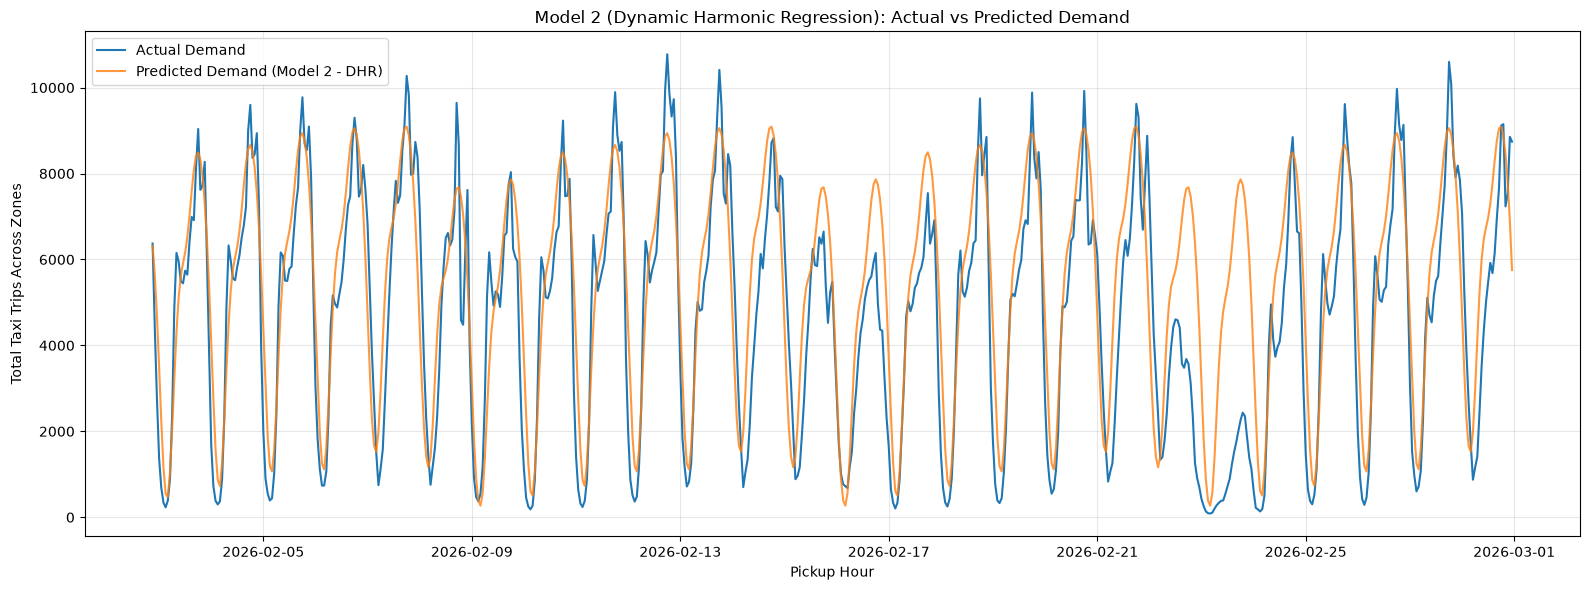

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "timeSeries":
    root = root.parent

predictions = pd.read_csv(
    root / "timeSeries/results/model_2/predictions.csv",
    parse_dates=["pickup_hour"]
)

test_predictions = predictions[
    (predictions["split"] == "test") &
    (predictions["model"] != "SeasonalNaive168")
].copy()

hourly_df = (
    test_predictions
    .groupby("pickup_hour", as_index=False)
    .agg(
        actual=("actual", "sum"),
        predicted=("predicted", "sum")
    )
    .sort_values("pickup_hour")
)

plt.figure(figsize=(16, 6))
plt.plot(hourly_df["pickup_hour"], hourly_df["actual"], label="Actual Demand")
plt.plot(
    hourly_df["pickup_hour"],
    hourly_df["predicted"],
    label="Predicted Demand (Model 2 - DHR)",
    alpha=0.8
)
plt.title("Model 2 (Dynamic Harmonic Regression): Actual vs Predicted Demand")
plt.xlabel("Pickup Hour")
plt.ylabel("Total Taxi Trips Across Zones")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()